# Task 4 eda_near_duplicate_v3
Audit whether **visually near-identical screenshots** can cross validation folds. The current model folds group only by exact `image_sha256`, which keeps byte-identical files together but not re-encoded, resized, recropped, or neighbouring stream captures.

Steps: hash every image (SHA-256, pHash, dHash) → find close Train pairs → inspect distance bands by eye → choose thresholds → merge pairs into `source_group` → measure how much the existing fold 1 is exposed → save one dataset.

**Rules.** Grouping uses Train only. Test hashes are computed only for a descriptive Train/Test near-duplicate check, like the earlier exact-hash check; nothing here fits a model or uses Test labels (there are none).

In [3]:
from pathlib import Path
import sys, hashlib
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"
RAW = SRC / "task4" / "data" / "raw"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.fft import dctn
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from src.pipeline.random_seed import set_seed
from src.pipeline.save_data import save_data
SEED = set_seed()
LABELS = {0: "7-11k", 1: "fiveN", 2: "freefried", 3: "pube", 4: "roblock"}
SUBSET = None  # set an int only for a quick smoke run; must be None for the saved dataset

train = pd.read_csv(RAW / "train.csv")
test = pd.read_csv(RAW / "test.csv")
assert train.columns.tolist() == test.columns.tolist() == ["id", "file_name", "label"]
assert train.id.is_unique and test.id.is_unique and train.file_name.is_unique
assert train.label.notna().all() and test.label.isna().all()
assert set(train.label.astype(int)) == set(LABELS)
if SUBSET:
    train, test = train.head(SUBSET).copy(), test.head(SUBSET // 2).copy()
train["class"] = train.label.astype(int).map(LABELS)
print("Train/Test rows:", len(train), len(test))

Train/Test rows: 31546 25889


## 1. Hash every image
- **SHA-256** reproduces the existing exact-file grouping.
- **dHash** (9×8 grayscale, compare neighbours) catches re-encoding and small brightness changes.
- **pHash** (32×32 grayscale → 2-D DCT → 8×8 low frequencies vs their median) is more tolerant of resizing and compression.

Both perceptual hashes are 64-bit integers; distance is the Hamming distance (0 = same, 64 = opposite). Images of the same game share UI layout, so small distances can also come from **different screenshots of one game**. The thresholds must be chosen by looking at pairs, not assumed.

In [4]:
def dhash(gray: Image.Image) -> np.uint64:
    a = np.asarray(gray.resize((9, 8), Image.Resampling.LANCZOS), dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).ravel()
    return np.packbits(bits).view(">u8")[0].astype(np.uint64)

def phash(gray: Image.Image) -> np.uint64:
    a = np.asarray(gray.resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float64)
    low = dctn(a, norm="ortho")[:8, :8].ravel()
    bits = low > np.median(low[1:])          # skip the DC term when choosing the median
    return np.packbits(bits).view(">u8")[0].astype(np.uint64)

def hash_split(frame: pd.DataFrame, split: str) -> pd.DataFrame:
    rows = []
    for name in frame.file_name:
        path = RAW / split / name
        data = path.read_bytes()
        with Image.open(path) as image:
            gray = image.convert("L")
            rows.append((hashlib.sha256(data).hexdigest(), phash(gray), dhash(gray), image.size))
    out = frame.copy()
    out["image_sha256"] = [r[0] for r in rows]
    out["phash"] = np.array([r[1] for r in rows], dtype=np.uint64)
    out["dhash"] = np.array([r[2] for r in rows], dtype=np.uint64)
    out["width"] = [r[3][0] for r in rows]
    out["height"] = [r[3][1] for r in rows]
    return out

train = hash_split(train, "train")
test = hash_split(test, "test")
print("Sizes:", train[["width", "height"]].value_counts().to_dict())
print("Repeated Train SHA-256:", int(train.image_sha256.duplicated().sum()))
print("Exact Train/Test SHA-256 overlap:", len(set(train.image_sha256) & set(test.image_sha256)))
print("Repeated Train pHash values:", int(train.phash.duplicated().sum()))

Sizes: {(230, 120): 31546}
Repeated Train SHA-256: 0
Exact Train/Test SHA-256 overlap: 0
Repeated Train pHash values: 45


## 2. Nearest neighbours and candidate pairs
Every Train image is compared with every other Train image in chunks (XOR, then bit count). The result keeps the nearest-neighbour distance per image and every pair up to `CANDIDATE_MAX` for later inspection.

Candidate pHash pairs <= 12: 146542
            pairs  same_label
phash_dist                   
0             117       1.000
2             384       0.997
4            1412       0.989
6            3950       0.956
8           10642       0.859
10          30564       0.678
12          99473       0.497


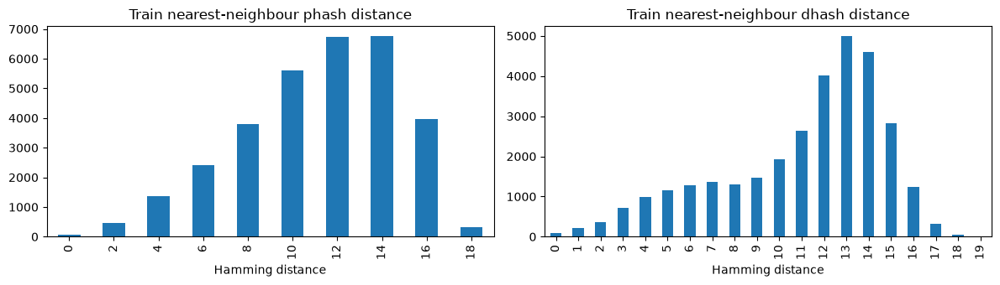

In [5]:
CANDIDATE_MAX = 12   # generous: only for inspection, not the final grouping rule

def hamming_block(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    return np.bitwise_count(a[:, None] ^ b[None, :]).astype(np.uint8)

def near_pairs(a: np.ndarray, b: np.ndarray | None = None, max_dist: int = CANDIDATE_MAX, chunk: int = 512):
    same = b is None
    b = a if same else b
    nearest = np.full(len(a), 64, dtype=np.uint8)
    found = []
    for start in range(0, len(a), chunk):
        d = hamming_block(a[start:start + chunk], b)
        if same:
            rows = np.arange(d.shape[0]); d[rows, start + rows] = 64   # ignore self
        nearest[start:start + chunk] = d.min(axis=1)
        i, j = np.nonzero(d <= max_dist)
        i = i + start
        keep = (j > i) if same else np.ones_like(i, dtype=bool)
        found.append(pd.DataFrame({"i": i[keep], "j": j[keep], "dist": d[i[keep] - start, j[keep]]}))
    return nearest, pd.concat(found, ignore_index=True)

ph, dh = train.phash.to_numpy(), train.dhash.to_numpy()
train["nn_phash_dist"], pairs = near_pairs(ph)
train["nn_dhash_dist"], _ = near_pairs(dh, max_dist=0)
pairs = pairs.rename(columns={"dist": "phash_dist"})
pairs["dhash_dist"] = np.bitwise_count(dh[pairs.i] ^ dh[pairs.j]).astype(np.uint8)
pairs["same_label"] = train.label.to_numpy()[pairs.i] == train.label.to_numpy()[pairs.j]
print("Candidate pHash pairs <= %d:" % CANDIDATE_MAX, len(pairs))
print(pairs.groupby("phash_dist").agg(pairs=("i", "size"), same_label=("same_label", "mean")).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for axis, col in zip(axes, ("nn_phash_dist", "nn_dhash_dist")):
    train[col].value_counts().sort_index().plot.bar(ax=axis)
    axis.set_title(f"Train nearest-neighbour {col.split('_')[1]} distance"); axis.set_xlabel("Hamming distance")
plt.tight_layout(); plt.show()

## 3. Look at pairs by distance band
This is the decision step. For each band, ask: **are these the same underlying capture** (same scene/moment, differing only by crop, scale, compression, brightness) or **merely the same game** (same HUD, different moment)? Choose the largest band that is still mostly the same capture. Re-run with a different `seed` to see other samples.

=== pHash distance 0-2: showing 6 of 501 pairs (same-label share in band 1.00) ===
 #  left_id   left_file left_class right_id  right_file right_class  phash_dist  dhash_dist  same_label
 1 PLY14334 sibp7nd.jpg      7-11k PLY29425 su7u3ni.jpg       7-11k           0          19        True
 2 PLY01861 srcgtay.jpg      7-11k PLY19699 shjsp0r.jpg       7-11k           2          23        True
 3 PLY15375 s2m10vd.jpg      7-11k PLY19604 sdgp6sz.jpg       7-11k           2           2        True
 4 PLY05040 s5e2589.jpg      7-11k PLY26268 s4imtux.jpg       7-11k           2           1        True
 5 PLY03115 s2z8nws.jpg      7-11k PLY15509 sy94i2o.jpg       7-11k           0          25        True
 6 PLY16573 srp3ijg.jpg      7-11k PLY21382 sgset58.jpg       7-11k           2          33        True


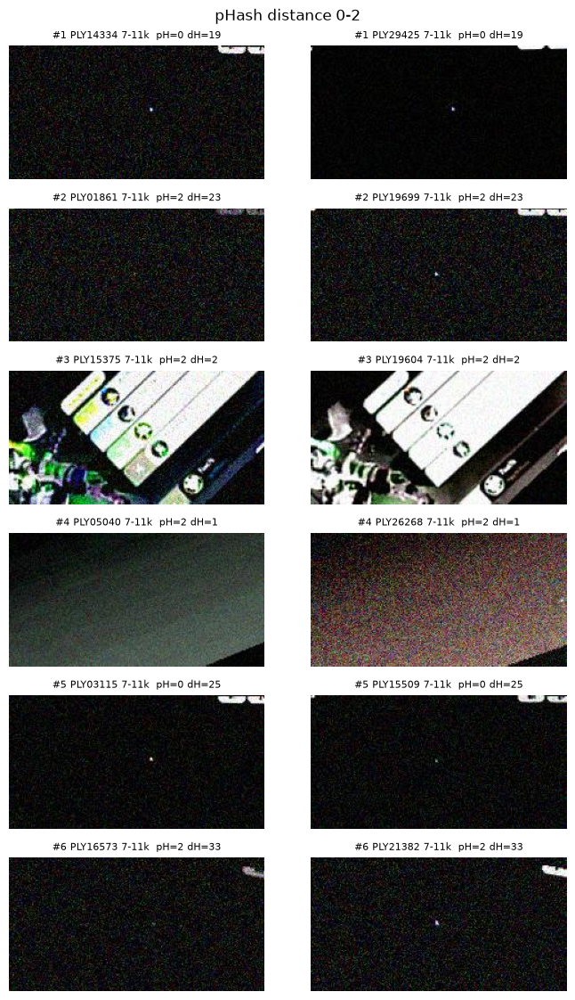

=== pHash distance 3-5: showing 6 of 1412 pairs (same-label share in band 0.99) ===
 #  left_id   left_file left_class right_id  right_file right_class  phash_dist  dhash_dist  same_label
 1 PLY10053 ssoq14c.jpg      7-11k PLY27935 slt5gwa.jpg       7-11k           4          12        True
 2 PLY11957 sccs2ok.jpg      7-11k PLY30452 s9w4fe0.jpg       7-11k           4           5        True
 3 PLY03802 sy4tv5s.jpg      7-11k PLY25282 sk7635e.jpg       7-11k           4          10        True
 4 PLY02092 sj39ff4.jpg      7-11k PLY18951 svumqz6.jpg       7-11k           4          14        True
 5 PLY02191 sab0yy2.jpg      7-11k PLY19939 sybkxvs.jpg       7-11k           4          16        True
 6 PLY11056 suddcnb.jpg      7-11k PLY15061 s49y82h.jpg       7-11k           4          10        True


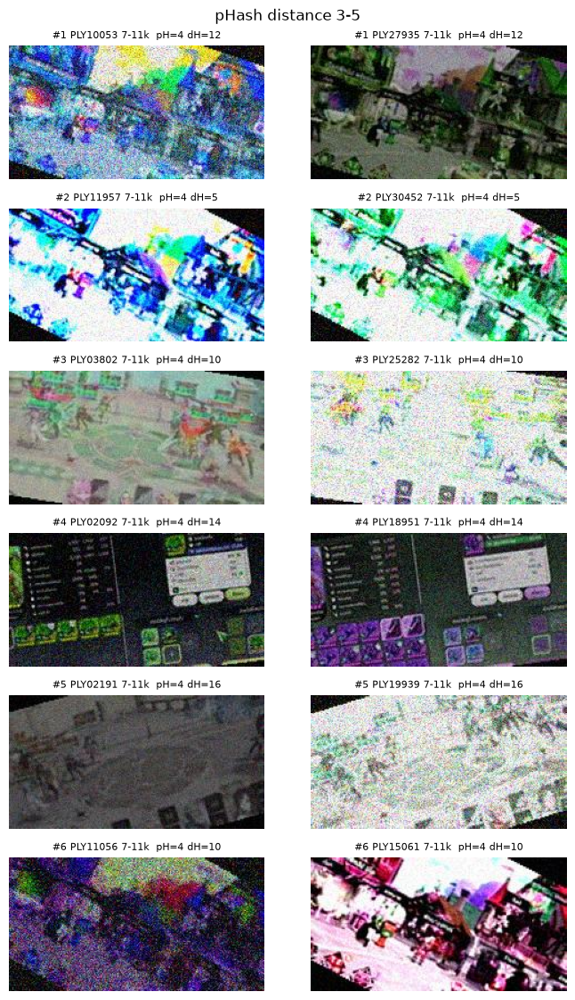

=== pHash distance 6-8: showing 6 of 14592 pairs (same-label share in band 0.89) ===
 #  left_id   left_file left_class right_id  right_file right_class  phash_dist  dhash_dist  same_label
 1 PLY05410 svmy64j.jpg      7-11k PLY14470 s4yly76.jpg       fiveN           8          27       False
 2 PLY11652 skiecsd.jpg    roblock PLY25918 sdx8pcu.jpg       7-11k           8          22       False
 3 PLY01062 sjero1p.jpg    roblock PLY30150 s3jy8z9.jpg     roblock           8           4        True
 4 PLY25798 sjqmv1o.jpg       pube PLY29756 s3xl3qd.jpg       7-11k           8          29       False
 5 PLY18083 sqip0wi.jpg      7-11k PLY19996 silqh4u.jpg       7-11k           8           3        True
 6 PLY01028 sf3zb5w.jpg      fiveN PLY12415 s5obzk8.jpg        pube           8          23       False


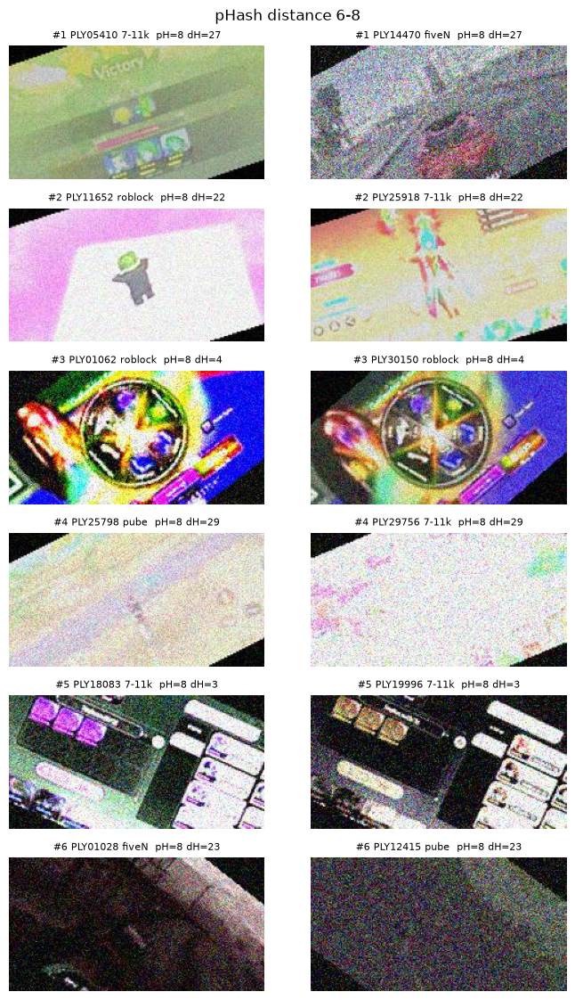

=== pHash distance 9-12: showing 6 of 130037 pairs (same-label share in band 0.54) ===
 #  left_id   left_file left_class right_id  right_file right_class  phash_dist  dhash_dist  same_label
 1 PLY04565 syajuik.jpg    roblock PLY29414 sghbcf9.jpg       7-11k          12          24       False
 2 PLY07927 sicahk0.jpg    roblock PLY29307 seevtgf.jpg        pube          10          23       False
 3 PLY12138 se8mn24.jpg      7-11k PLY28717 s4tv498.jpg        pube          12          13       False
 4 PLY14719 sv77mey.jpg      7-11k PLY25695 s49mf3f.jpg   freefried          12          32       False
 5 PLY00371 spnvmu1.jpg      fiveN PLY07732 s3soclq.jpg       7-11k          12          24       False
 6 PLY14696 spekcsv.jpg      7-11k PLY21705 sw4o8pn.jpg       7-11k          12           6        True


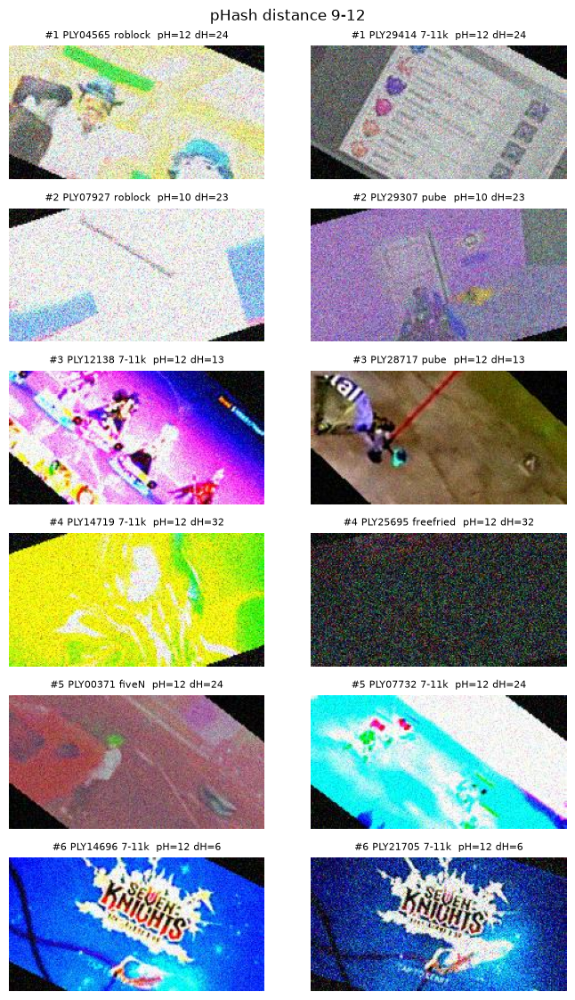

In [6]:
def show_pairs(frame: pd.DataFrame, title: str, n: int = 6, seed: int = SEED) -> pd.DataFrame:
    """Plot n sampled pairs side by side and print the same pairs as a text table.

    Row numbers (#) match between the figure and the table; returns the table so
    you can add a verdict column (A/B/C/D) and tally it.
    """
    if frame.empty:
        print(title, "- no pairs"); return pd.DataFrame()
    sample = frame.sample(min(n, len(frame)), random_state=seed).reset_index(drop=True)
    table = pd.DataFrame({
        "#": np.arange(1, len(sample) + 1),
        "left_id": train.id.to_numpy()[sample.i], "left_file": train.file_name.to_numpy()[sample.i],
        "left_class": train["class"].to_numpy()[sample.i],
        "right_id": train.id.to_numpy()[sample.j], "right_file": train.file_name.to_numpy()[sample.j],
        "right_class": train["class"].to_numpy()[sample.j],
        "phash_dist": sample.phash_dist.to_numpy(), "dhash_dist": sample.dhash_dist.to_numpy(),
        "same_label": sample.same_label.to_numpy(),
    })
    print(f"=== {title}: showing {len(sample)} of {len(frame)} pairs "
          f"(same-label share in band {frame.same_label.mean():.2f}) ===")
    with pd.option_context("display.width", 200, "display.max_columns", None):
        print(table.to_string(index=False))

    fig, axes = plt.subplots(len(sample), 2, figsize=(7, 1.9 * len(sample)), squeeze=False)
    for row, (_, p) in zip(axes, sample.iterrows()):
        for axis, k in zip(row, (p.i, p.j)):
            with Image.open(RAW / "train" / train.file_name.iat[k]) as image:
                axis.imshow(image.convert("RGB"))
            axis.set_title(f"#{_ + 1} {train.id.iat[k]} {train['class'].iat[k]}  pH={p.phash_dist} dH={p.dhash_dist}", fontsize=8)
            axis.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()
    return table

band_tables = {}
for low, high in ((0, 2), (3, 5), (6, 8), (9, 12)):
    band_tables[(low, high)] = show_pairs(pairs[pairs.phash_dist.between(low, high)], f"pHash distance {low}-{high}")

### Pairs whose labels disagree
A visually near-identical pair with different labels is either a genuinely ambiguous screenshot or label noise. Either way it is worth reporting.

Label-conflicting candidate pairs: 61598
phash_dist
2         1
4        16
6       174
8      1502
10     9856
12    50049
=== Label-conflicting pairs with pHash <= 6: showing 8 of 191 pairs (same-label share in band 0.00) ===
 #  left_id   left_file left_class right_id  right_file right_class  phash_dist  dhash_dist  same_label
 1 PLY15980 scd41wf.jpg       pube PLY27140 sik1uwi.jpg       7-11k           6          29       False
 2 PLY06080 szv715g.jpg      7-11k PLY14433 s9t8xln.jpg        pube           6          34       False
 3 PLY16779 s51iu5h.jpg  freefried PLY24859 sheghfv.jpg       7-11k           6          35       False
 4 PLY04685 sbb27nv.jpg  freefried PLY30442 stqsk4h.jpg       7-11k           6          18       False
 5 PLY04130 sjr3uj8.jpg    roblock PLY25798 sjqmv1o.jpg        pube           4          27       False
 6 PLY01489 sk5fdlc.jpg  freefried PLY30685 skq79ne.jpg       7-11k           6          24       False
 7 PLY00720 sd6vhqa.jpg      7-11k PLY14730 

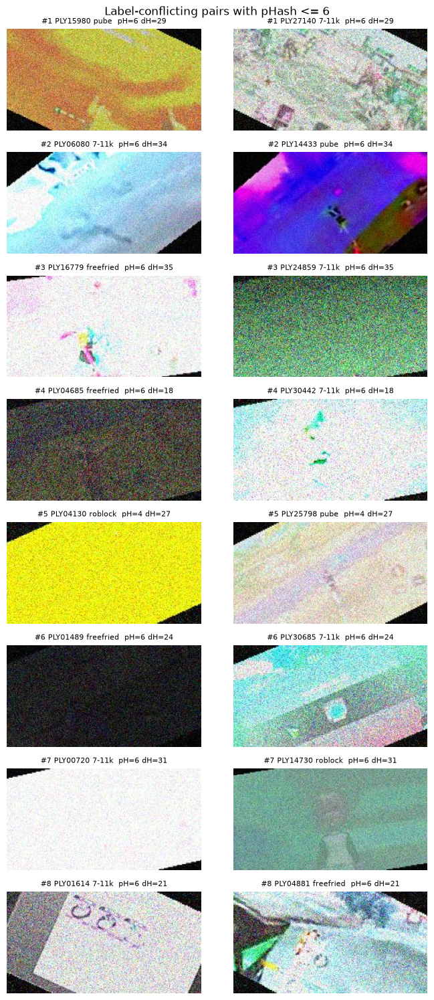

,#,left_id,left_file,left_class,right_id,right_file,right_class,phash_dist,dhash_dist,same_label
0,1,PLY15980,scd41wf.jpg,pube,PLY27140,sik1uwi.jpg,7-11k,6,29,False
1,2,PLY06080,szv715g.jpg,7-11k,PLY14433,s9t8xln.jpg,pube,6,34,False
2,3,PLY16779,s51iu5h.jpg,freefried,PLY24859,sheghfv.jpg,7-11k,6,35,False
3,4,PLY04685,sbb27nv.jpg,freefried,PLY30442,stqsk4h.jpg,7-11k,6,18,False
4,5,PLY04130,sjr3uj8.jpg,roblock,PLY25798,sjqmv1o.jpg,pube,4,27,False
5,6,PLY01489,sk5fdlc.jpg,freefried,PLY30685,skq79ne.jpg,7-11k,6,24,False
6,7,PLY00720,sd6vhqa.jpg,7-11k,PLY14730,sqf1z42.jpg,roblock,6,31,False
7,8,PLY01614,ssg25s9.jpg,7-11k,PLY04881,sclax7t.jpg,freefried,6,21,False


In [7]:
conflicts = pairs[~pairs.same_label]
print("Label-conflicting candidate pairs:", len(conflicts))
print(conflicts.groupby("phash_dist").size().to_string())
show_pairs(conflicts[conflicts.phash_dist <= 6], "Label-conflicting pairs with pHash <= 6", n=8)

### Threshold sweep
Compare candidate thresholds before choosing them. For each pair of limits: links, images that join a multi-image group, the largest group (a very large one means chained, too-loose links), groups with more than one label, and how many fold-1 validation images would have a near-duplicate in fold-1 train. Fold 1 is rebuilt exactly as in `build_model_v2` from Train labels and image hashes only; no model predictions are used here.

In [12]:
def grouping(p_max: int, d_max: int):
    linked = pairs[(pairs.phash_dist <= p_max) & (pairs.dhash_dist <= d_max)]
    graph = coo_matrix((np.ones(len(linked)), (linked.i, linked.j)), shape=(len(train), len(train)))
    return linked, connected_components(graph, directed=False)[1]

fold_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
fold1_dev, fold1_valid = next(fold_splitter.split(train, train["class"], train.image_sha256))
classes = pd.Series(train["class"].to_numpy())
rows = []
for p_max in (0, 2, 4, 6, 8):
    for d_max in (64, 16, 10):
        linked, comp = grouping(p_max, d_max)
        sizes = np.bincount(comp)
        exposed = np.isin(comp[fold1_valid], np.unique(comp[fold1_dev]))
        rows.append({"PHASH_MAX": p_max, "DHASH_MAX": d_max, "links": len(linked),
                     "images_in_groups": int(sizes[sizes > 1].sum()), "largest_group": int(sizes.max()),
                     "mixed_label_groups": int((classes.groupby(comp).nunique() > 1).sum()),
                     "fold1_valid_exposed": int(exposed.sum())})
sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))

 PHASH_MAX  DHASH_MAX  links  images_in_groups  largest_group  mixed_label_groups  fold1_valid_exposed
         0         64    117                73             12                   0                   11
         0         16     39                65              7                   0                   11
         0         10     21                39              3                   0                    7
         2         64    501               547             14                   1                   89
         2         16    346               508              9                   0                   82
         2         10    289               433              9                   0                   69
         4         64   1913              1928             51                  12                  339
         4         16   1602              1806             50                   2                  316
         4         10   1339              1537             45            

## 4. Choose thresholds and build `source_group`
A pair is linked only if **both** hashes are close, which reduces same-game false matches. Linked images are merged with connected components, so chains (A≈B, B≈C) form one group. Record the reasoning for the chosen values in the card below.

In [8]:
PHASH_MAX = 4   
DHASH_MAX = 16  
THRESHOLD_REASON = "pHash <= 4 keeps same-label share >= 0.989 and sampled pairs were mostly the same capture or adjacent frames; pHash 0-2 pairs with dHash > 16 (155 of 501) looked like different scenes, so DHASH_MAX = 16. pHash 6 adds 76 mixed-label groups and 8 chains a 3,950-image group."

links = pairs[(pairs.phash_dist <= PHASH_MAX) & (pairs.dhash_dist <= DHASH_MAX)]
graph = coo_matrix((np.ones(len(links)), (links.i, links.j)), shape=(len(train), len(train)))
n_groups, component = connected_components(graph, directed=False)
train["source_group"] = [f"g{c:05d}" for c in component]
sizes = train.source_group.value_counts()
print("Links:", len(links), "| groups:", n_groups, "| images in multi-image groups:", int(sizes[sizes > 1].sum()))
print("Group size distribution:", sizes.value_counts().sort_index().to_dict())
mixed = train.groupby("source_group")["class"].nunique()
print("Groups with more than one label:", int((mixed > 1).sum()))
print("Multi-image share by class:")
print(train.assign(multi=train.source_group.map(sizes) > 1).groupby("class").multi.mean().round(4).to_string())

Links: 1602 | groups: 30351 | images in multi-image groups: 1806
Group size distribution: {1: 29740, 2: 428, 3: 90, 4: 34, 5: 16, 6: 15, 7: 6, 8: 3, 9: 4, 10: 3, 11: 1, 13: 1, 14: 2, 15: 3, 16: 1, 20: 1, 27: 1, 32: 1, 50: 1}
Groups with more than one label: 2
Multi-image share by class:
class
7-11k        0.1357
fiveN        0.0120
freefried    0.0032
pube         0.0010
roblock      0.0132


### Linked pairs whose labels disagree
These pairs pass **both** chosen thresholds yet carry different labels, so they create the mixed-label groups counted above. Inspect every one: if the two images are the same capture, one label is probably wrong (report it as possible label noise); if they are different scenes, the thresholds are too loose for this kind of image.

Linked label-conflicting pairs: 4
=== Label-conflicting pairs that were linked: showing 4 of 4 pairs (same-label share in band 0.00) ===
 #  left_id   left_file left_class right_id  right_file right_class  phash_dist  dhash_dist  same_label
 1 PLY03613 s57npd3.jpg    roblock PLY04719 sqwup70.jpg       7-11k           4          10       False
 2 PLY11408 scobzcd.jpg    roblock PLY19088 sfykwn7.jpg       7-11k           4           9       False
 3 PLY02786 si97cvi.jpg      7-11k PLY11408 scobzcd.jpg     roblock           4          14       False
 4 PLY06207 sbxo0on.jpg    roblock PLY30885 su0vdwu.jpg       7-11k           4          16       False


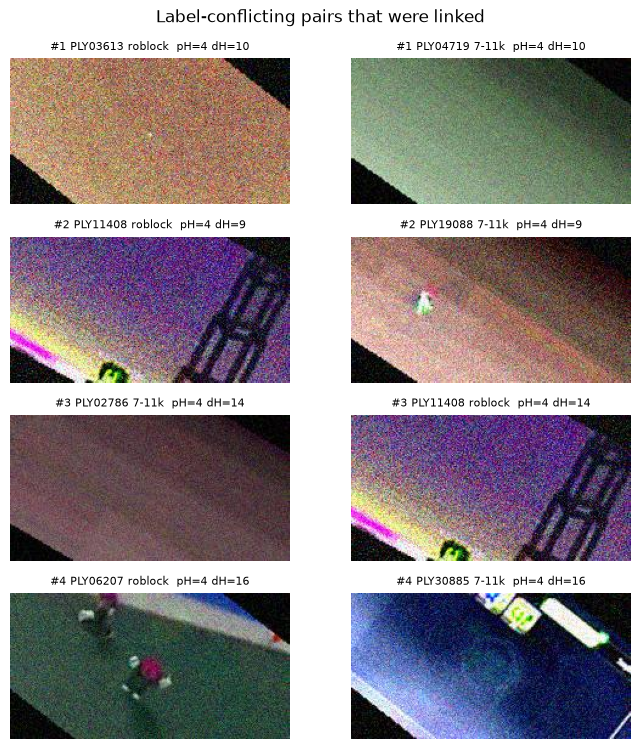

In [13]:
suspect = pairs[(~pairs.same_label) & (pairs.phash_dist <= PHASH_MAX) & (pairs.dhash_dist <= DHASH_MAX)]
print("Linked label-conflicting pairs:", len(suspect))
suspect_table = show_pairs(suspect, "Label-conflicting pairs that were linked", n=min(len(suspect), 20))

## 5. How exposed is the existing fold 1?
Rebuild the model notebook's fold 1 exactly (`StratifiedGroupKFold(5, shuffle=True, random_state=SEED)` on class names, grouped by `image_sha256`) and count validation images whose `source_group` also has an image in the training part. A large share means the reported grouped-fold scores could be optimistic; the model notebook then retrains with `source_group` as the group.

In [9]:
if SUBSET is None:
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    dev_idx, valid_idx = next(splitter.split(train, train["class"], train.image_sha256))
    assert (len(dev_idx), len(valid_idx)) == (25236, 6310), "fold 1 no longer matches build_model_v2"
    train_groups = set(train.source_group.iloc[dev_idx])
    exposed = train.source_group.iloc[valid_idx].isin(train_groups).to_numpy()
    print(f"Fold-1 validation images with a near-duplicate in fold-1 train: {exposed.sum()} / {len(valid_idx)} ({exposed.mean():.2%})")
    print(train.iloc[valid_idx].assign(exposed=exposed).groupby("class").exposed.mean().round(4).to_string())
else:
    print("Skipped on SUBSET smoke run")

Fold-1 validation images with a near-duplicate in fold-1 train: 316 / 6310 (5.01%)
class
7-11k        0.1183
fiveN        0.0102
freefried    0.0036
pube         0.0017
roblock      0.0110


## 6. Descriptive Train/Test check
Nearest Train pHash distance for each Test image, reported only as a distribution. It is not used for fitting, selection, or labels.

In [10]:
test["nn_train_phash_dist"], _ = near_pairs(test.phash.to_numpy(), ph, max_dist=0)
print("Test images with a Train image at pHash <= PHASH_MAX:", int((test.nn_train_phash_dist <= PHASH_MAX).sum()), "/", len(test))
print(test.nn_train_phash_dist.value_counts().sort_index().head(15).to_string())

Test images with a Train image at pHash <= PHASH_MAX: 73 / 25889
nn_train_phash_dist
0        1
2       12
4       60
6      284
8     1403
10    3874
12    6297
14    8112
16    5379
18     467


## 7. Save the dataset
One artifact: manifests plus hashes and `source_group`. The model notebook reads it by the paths in its JSON card. Hashes are stored as unsigned 64-bit integers.

In [11]:
assert SUBSET is None, "never save a smoke-run subset"
assert THRESHOLD_REASON.strip(), "write THRESHOLD_REASON in section 4 after inspecting the pairs"
train_out = train[["id", "file_name", "label", "class", "image_sha256", "phash", "dhash",
                   "width", "height", "nn_phash_dist", "nn_dhash_dist", "source_group"]]
test_out = test[["id", "file_name", "image_sha256", "phash", "dhash", "width", "height", "nn_train_phash_dist"]]
info = save_data(
    task=4,
    name="eda_near_duplicate_v3",
    train=train_out,
    test=test_out,
    card={
        "source": "task4/data/raw train.csv, test.csv and images",
        "preparation": "SHA-256, 64-bit pHash (32x32 DCT) and dHash (9x8) per image; Train pairs linked when pHash and dHash distances are both within the chosen thresholds; connected components give source_group.",
        "thresholds": {"phash_max": PHASH_MAX, "dhash_max": DHASH_MAX},
        "threshold_reason": THRESHOLD_REASON,
        "test_use": "Hashes and nearest-Train distance only, descriptive; no fitting.",
    },
    format="parquet",
)
print(info["splits"]["train"]["path"]); print(info["splits"]["test"]["path"])

task4/data/eda/eda_near_duplicate_v3-train.parquet
task4/data/eda/eda_near_duplicate_v3-test.parquet
